In [1]:
import importlib

import pandas as pd

from DataAnalysis.functions import computationTime_analysis

from DataAnalysis.functions.computationTime_analysis import *

%matplotlib inline

## Choose file

In [30]:
filename = "YYYY0625_HHmmss_combined_HPC.csv"
df, data = get_df_and_data(filename)
print(f'approximation: {data["approx"]}, level: {data["approx_level"]}, npoints: {data["npoints"]}')
df.head()

approximation: none, level: 1, npoints: 4000


,Name,InChI,FieldStrength,Index,spin_matrix,ID,n_spins,spectrum,computation_time,ppm
0,AMP,InChI=1S/C10H14N5O7P/c11-8-5-9(13-2-12-8)15(3-...,499.84,"['26', '27', '31', '30', '29', '28', '24', '25']","""[ 8.112 0. 0. 0. 0. 0....",bmse000005,8,"""[0.00567878118780836;0.005679014797655;0.0056...",4.480773,"""[-1 -0.996999249812453 -0.993998499624906 -0...."
1,ATP,InChI=1S/C10H16N5O13P3/c11-8-5-9(13-2-12-8)15(...,499.84,"['34', '35', '39', '38', '37', '36', '32', '33']","""[ 8.122 0. 0. 0. 0. 0....",bmse000006,8,"""[0.00370062890899806;0.00370055580809659;0.00...",4.009268,"""[-1 -0.996999249812453 -0.993998499624906 -0...."
2,Adenine,InChI=1S/C5H5N5/c6-4-3-5(9-1-7-3)10-2-8-4/h1-2...,499.84,"['11', '12']","""[8.141 0. ];[0. 8.005]""",bmse000060,2,"""[0.00367961011793641;0.00367955658104921;0.00...",0.558675,"""[-1 -0.996999249812453 -0.993998499624906 -0...."
3,Adenosine,InChI=1S/C10H13N5O4/c11-8-5-9(13-2-12-8)15(3-1...,499.84,"['22', '23', '27', '26', '25', '24', '20', '21']","""[ 8.192 0. 0. 0. 0. 0....",bmse000061,8,"""[0.00364077242536434;0.00364087060399012;0.00...",3.854597,"""[-1 -0.996999249812453 -0.993998499624906 -0...."
4,Agmatine,"InChI=1S/C5H14N4/c6-3-1-2-4-9-5(7)8/h1-4,6H2,(...",499.84,"['10', '11', '12', '13', '16', '17', '14', '15']","""[ 1.732 -14.168 11.38 5.131 0. 0....",bmse000063,8,"""[0.000158338947424724;0.00015832259037916;0.0...",103.501544,"""[-1 -0.996999249812453 -0.993998499624906 -0...."


In [3]:
df['spectrum'] = df['spectrum'].fillna(r'"[0]"') # Prevent error in processing later
df.loc[df['spectrum']== r'"[0]"']

,Name,InChI,FieldStrength,Index,spin_matrix,ID,n_spins,spectrum,computation_time,ppm
45,"4-Amino-1,2-oxazolidin-3-one","InChI=1S/C3H6N2O2/c4-2-1-7-5-3(2)6/h2H,1,4H2,(...",499.84,"['8', '9', '10', '8a', '9a', '10a']","""[ 4.495 -9.878 7.792 0. 0. 0....",bmse001150,3,"""[0]""",0.009389,NaN
349,Formiminoglycine,"InChI=1S/C3H6N2O2/c4-2-5-1-3(6)7/h2H,1H2,(H2,4...",499.84,"['8', '9', '10', '8a', '9a', '10a']","""[ 3.922 -12.4 0. 0. 0. 0....",bmse001134,3,"""[0]""",0.005529,NaN


Here you can see the rows were the code failed to compute the spectra.

 ## n_spins vs. comp_time

In [4]:
total_time = df["computation_time"].sum()
rest = total_time % 3600
print(f'total computation time: {int(total_time//3600)}h {int(rest//60)}min')

total computation time: 19h 59min


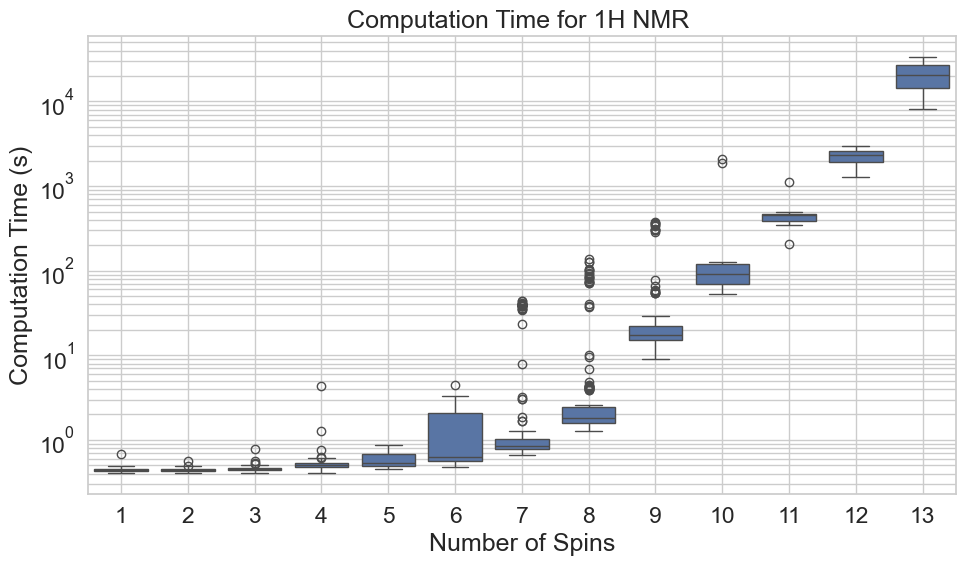

In [28]:
importlib.reload(computationTime_analysis)

df = df[df['spectrum'] != '"[0]"'].copy()
df = df[df['n_spins'] != 0].copy()
output_filename=""
#For similar computation times over spins: set yscale 'linear'
computationTime_analysis.boxplot(df, filename=output_filename, yscale='log', filename_plot='computation_time_log_scale.png', save=False)

## J-couplings vs. comp_time

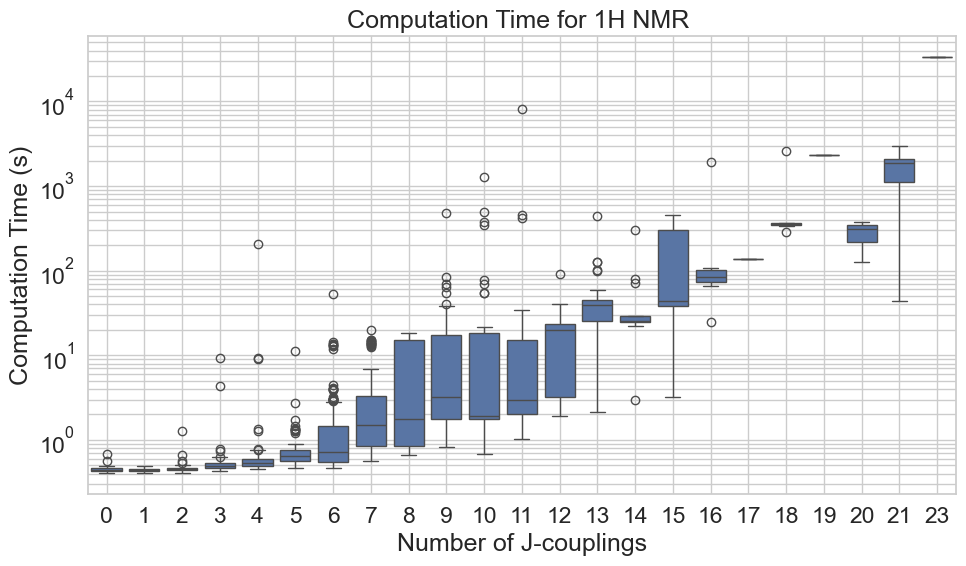

In [6]:
importlib.reload(computationTime_analysis) #just here if you change the function and don't want to reload the whole kernel

# Calculate number of J-couplings and add it to the dataframe
df['non_zero_spins'] = df['spin_matrix'].apply(count_non_zero_off_diagonal)

# plot
df = df[df['spectrum'] != '"[0]"'].copy() #ignore failed molecule
computationTime_analysis.boxplot(df, filename=filename, yscale='log', filename_plot='computation_time_log_scale.png', column='non_zero_spins', save=False)

## n_spins vs. J-coupling vs. comp_time

In [7]:
df.loc[df["non_zero_spins"]>=20]

,Name,InChI,FieldStrength,Index,spin_matrix,ID,n_spins,spectrum,computation_time,ppm,non_zero_spins
82,Butanol,"InChI=1S/C4H10O/c1-2-3-4-5/h5H,2-4H2,1H3",499.84,"['6', '7', '8', '9', '10', '11', '12', '13', '...","""[ 0.89 -12.5 -12.5 7.382 7.382 0....",bmse000447,9,"""[0.00113256387047609;0.00113246156656221;0.00...",380.858620,"""[-1 -0.996999249812453 -0.993998499624906 -0....",20
904,Trans-2-3-dimethylacrylic-acid,"InChI=1S/C5H8O2/c1-3-4(2)5(6)7/h3H,1-2H3,(H,6,...",499.84,"['8', '9', '10', '14', '11', '12', '13']","""[ 1.71 -14.9 -14.9 7.05 1.028 1....",bmse000727,7,"""[1.34302609967404e-05;1.34209641678912e-05;1....",43.724617,"""[-1 -0.996999249812453 -0.993998499624906 -0....",21
974,Valeric-acid,"InChI=1S/C5H10O2/c1-2-3-4-5(6)7/h2-4H2,1H3,(H,...",499.84,"['8', '9', '10', '11', '12', '13', '14', '15',...","""[ 0.876 -12.5 -12.5 7.409 7.409 0....",bmse000345,9,"""[0.00640190312903171;0.00640211780242527;0.00...",312.370446,"""[-1 -0.996999249812453 -0.993998499624906 -0....",20
980,6-Aminohexanoic-acid,"InChI=1S/C6H13NO2/c7-5-3-1-2-4-6(8)9/h1-5,7H2,...",499.84,"['10', '11', '16', '17', '12', '13', '14', '15...","""[ 1.369 -12.4 0. 0. 7.749 7....",bmse000394,10,"""[0.000234501145497161;0.000234562779889591;0....",1875.295994,"""[-1 -0.996999249812453 -0.993998499624906 -0....",21
986,Biphenyl,InChI=1S/C12H10/c1-3-7-11(8-4-1)12-9-5-2-6-10-...,400.13,"['13', '15', '19', '20', '16', '14', '17', '21...","""[7.344 7.5 2. 2. 7.5 0. 0. 0....",bmse000506,10,"""[0.000433764463120313;0.000433726069966376;0....",125.564561,"""[-1 -0.996999249812453 -0.993998499624906 -0....",20
989,Cadaverine,InChI=1S/C5H14N2/c6-4-2-1-3-5-7/h1-7H2,499.84,"['8', '9', '10', '11', '14', '15', '12', '13',...","""[ 1.46 -12.4 5.909 10.257 0. 0....",bmse000072,10,"""[0.00435715629941465;0.00435722534544777;0.00...",2109.395940,"""[-1 -0.996999249812453 -0.993998499624906 -0....",21
997,(2-Butyl-5-chloro-1H-imidazol-4-yl)methanol,InChI=1S/C8H13ClN2O/c1-2-3-4-7-10-6(5-12)8(9)1...,600.01,"['13', '14', '15', '16', '17', '18', '19', '20...","""[ 0.871 -14. -14. 8.03 8.03 0....",Maybridge_Ro3_Fragment_05_H06,11,"""[0.00559244632196402;0.00559239728526063;0.00...",1114.065566,"""[-1 -0.996999249812453 -0.993998499624906 -0....",21
1003,(2-Butyl-1H-imidazol-4-yl)methanol,InChI=1S/C8H14N2O/c1-2-3-4-8-9-5-7(6-11)10-8/h...,600.01,"['12', '13', '14', '15', '16', '17', '18', '19...","""[ 0.886 -14. -14. 7.832 7.832 0....",Maybridge_Ro3_Fragment_02_E07,12,"""[0.00230961327991725;0.00230960706432582;0.00...",3013.003407,"""[-1 -0.996999249812453 -0.993998499624906 -0....",21
1005,Biotin,InChI=1S/C10H16N2O3S/c13-8(14)4-2-1-3-7-9-6(5-...,600.13,"['25', '26', '27', '29', '28', '21', '22', '17...","""[ 2.773 -13.193 1.091 0. 0. 0....",bmse000227,13,"""[0.00110140828381261;0.00110143307392472;0.00...",33415.968248,"""[-1 -0.996999249812453 -0.993998499624906 -0....",23


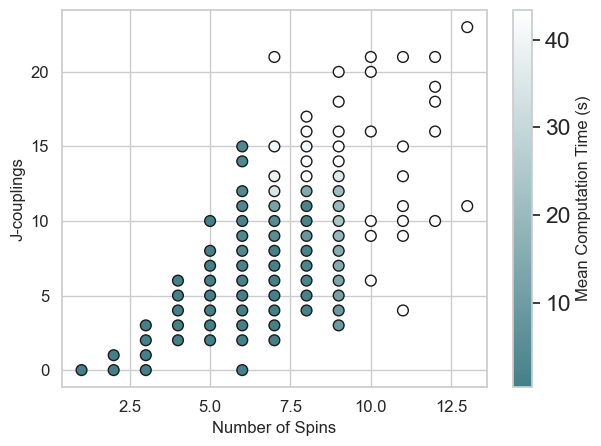

In [8]:
grouped_df = df.groupby(['n_spins', 'non_zero_spins'])['computation_time'].mean().reset_index()
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Compute a reasonable upper bound — e.g., 95th percentile
vmax = grouped_df["computation_time"].quantile(0.7)

custom_cmap = LinearSegmentedColormap.from_list(
    "custom_cmap", ["#448087", "#ffffff"]
)

sc = plt.scatter(
    grouped_df["n_spins"],
    grouped_df["non_zero_spins"],
    c=grouped_df["computation_time"],
    cmap=custom_cmap,
    edgecolor="k",
    s=60,
    vmin=grouped_df["computation_time"].min(),
    vmax=vmax  # limit color range
)

cbar = plt.colorbar(sc)
cbar.set_label("Mean Computation Time (s)", fontsize=12)

plt.xlabel("Number of Spins", fontsize=12)
plt.ylabel("J-couplings", fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.savefig("mean_computation_time_plot.png")
plt.show()

## Estimate computation time for bigger molecules

### Model 1: based on n_spins

This model expects computation time to grow in logarithmic scale to the number of spins. Molecule with six or fewer spins will be ignored.

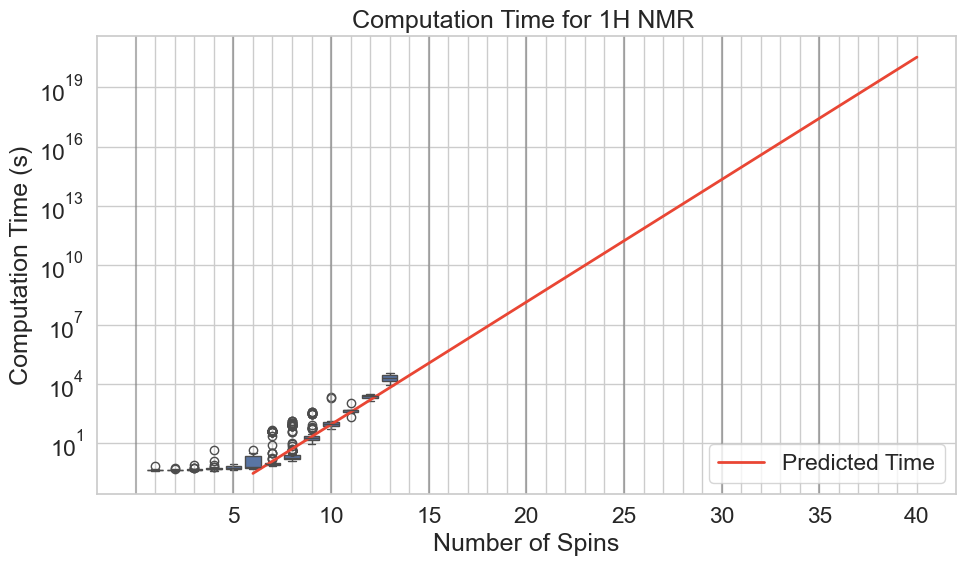

In [9]:
importlib.reload(computationTime_analysis) #if changes are made on that function
# & (df['n_spins']<= 12 )
filtered_df = df[(df['n_spins'] >= 7) ].copy() # ignore molecule with less than 7 spins
filtered_df = filtered_df[filtered_df['computation_time'] > 0] # ignore failed molecules

# Take the log of computation time
X = filtered_df[['n_spins']]
y_log = np.log(filtered_df['computation_time'])

# Fit linear model to log-transformed target
model = LinearRegression()
model.fit(X, y_log)
n_spins_range = np.arange(6, 41).reshape(-1, 1)
predicted_log_times = model.predict(pd.DataFrame(n_spins_range, columns=['n_spins']))

# Convert back to original scale
predicted_times = np.exp(predicted_log_times)
predicted_times = np.clip(predicted_times, 0, None)
m1_predictions_df = pd.DataFrame({
    'n_spins': n_spins_range.flatten(),
    'predicted_computation_time': predicted_times
})

computationTime_analysis.boxplot(df,
                                 yscale='log',
                                 filename_plot='computation_time_with_exponential_fit.png',
                                 save=True,
                                 regression_df=m1_predictions_df)

In [10]:
# Uncomment if you want to see the times more specific
#m1_predictions_df[:14]

### Model 2: more than just exponential

 The number of J-couplings grow approximately with ratio 1.13*n_spins (calculated with snippet beneath) and influence computation_time as well. I would therefore suggest an additional exponential growth of computation time from n_spins and a polynomial growth from J-couplings:

In [11]:
# find a fitting multiplier for n_J-couplings
# The 'multiplier' isn't used in the next snipped because it should be calculated based on the whole dataset
average_per_n_spins = df.groupby('n_spins')['non_zero_spins'].mean()
multiplier = df['non_zero_spins'].sum() / df['n_spins'].sum()
float(multiplier)
myComparisonModel =()

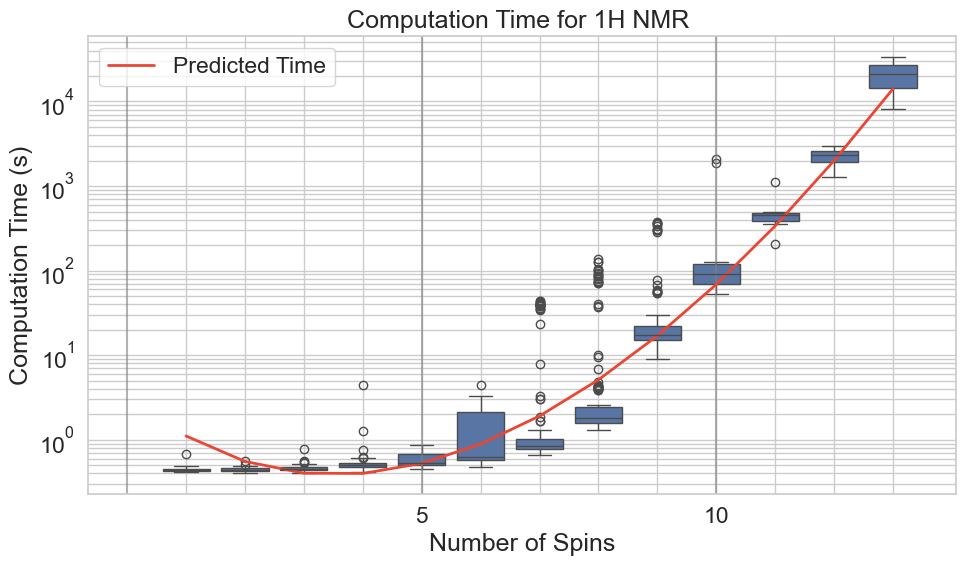

In [27]:
importlib.reload(computationTime_analysis)

filtered_df = df[(df['n_spins'] >= 1) & (df['n_spins'] <= 12) & (df['computation_time'] > 0)].copy()
filtered_df['X2'] = 1.13 * filtered_df['n_spins'] #1.13 = the calculated multiplier
filtered_df['X2_sq'] = filtered_df['X2']** 1.6       # 1.6 = a good fit for my data; for a far more precise prediction the exact amount of couplings should be taken in a multiple Regression Model.

# Feature matrix and target
X = filtered_df[['n_spins', 'X2_sq']]
y_log = np.log(filtered_df['computation_time'])

# Fit linear model to log target
model = LinearRegression()
model.fit(X, y_log)

# Prediction range
n_spins_range = np.arange(1, 14)
X2_range = 1.13* n_spins_range
X2_sq_range = X2_range ** 1.6
X_pred = pd.DataFrame({
    'n_spins': n_spins_range,
    'X2_sq': X2_sq_range
})

# Predict and exponentiate
predicted_log_times = model.predict(X_pred)
predicted_times = np.exp(predicted_log_times)

# Prepare prediction DataFrame
m2_predictions_df = pd.DataFrame({
    'n_spins': n_spins_range,
    'predicted_computation_time': predicted_times
})

# Plot
computationTime_analysis.boxplot(df,
                                 yscale='log',
                                 filename_plot='computation_time_with_exp_poly_fit.png',
                                 save=True,
                                 regression_df=m2_predictions_df)


You can more accuratly predict computation time with a ML model by taking J-couplings as a second variable, but then predictions about computation time can only be made after calculation spin-matrix (and then J-couplings) first.

In [13]:
# Uncomment if you want to see the times more specific
#m2_predictions_df

In [14]:
full_df = pd.read_csv("../data/temp_dataset.csv") # full GISSMO preprocessed
df_with_predictions = full_df.merge(
    m2_predictions_df[['n_spins', 'predicted_computation_time']],
    on='n_spins',
    how='left'  # keep all rows in df, even if no match found
)
total_seconds = df_with_predictions['predicted_computation_time'].sum()
total_hours = total_seconds / 3600
total_years = total_hours / (365 * 24)

print(f"Total predicted computation time: {total_years} years")

Total predicted computation time: 1.1811607373393372e+18 years
